# 04_evaluation.ipynb — Final Test Evaluation, Comparative Analysis & Error Diagnostics

**Module:** NB6057CEM Artificial Neural Networks — CW1 Practical  
**Task:** Task T4a & T4b — Final Model Evaluation, Multi-Seed Comparison & Diagnostics (14 marks)  
**Dataset:** MotionSense (A_DeviceMotion_data) — Malekzadeh et al. (2018/2019)  

---

### Coursework Brief Requirements (Tasks T4a & T4b)
The coursework brief specifies rigorous out-of-sample evaluation protocol:
1. **Unblinding Held-Out Test Data**: Evaluate models strictly once on the held-out test set (4 participants: 2 male, 2 female; 3,730 total windows) after freezing all architectures, hyperparameters, and preprocessing scalers. Test data was never used for tuning or model selection (Rule 7).
2. **Multi-Seed Stability (3 Seeds)**: Evaluate Random Forest, PyTorch MLP, and PyTorch 1D-CNN across three random seeds (0, 1, 2) to quantify performance variance and stochastic stability.
3. **Primary Metric**: Macro-averaged F1 score (`test_macro_f1`), complementary to overall accuracy, per-class precision/recall/F1, and row-normalised confusion matrices.
4. **Zero-Model Prediction Verification**: Recompute test macro-F1 directly from the saved prediction CSV files (`outputs/metrics/predictions/*.csv`) and prove exact match with `results_table.csv` without needing model weights.
5. **Class-Level & Confusion Diagnostics**: Identify top misclassifications and interpret the biophysical mechanisms underlying sensor confusions.
6. **Per-Subject Fairness & Demographics**: Evaluate performance across individual test participants to quantify demographic robustness and inter-subject variance.
7. **Visual Evidence**: Interpret existing evaluation figures (Figures 10 through 14) from `outputs/figures/`.

---

### Evidence Files
- **Results Table**: `outputs/metrics/results_table.csv`
- **Summary Metrics**: `outputs/metrics/results_summary.json`
- **Per-Window Prediction Files**: `outputs/metrics/predictions/*.csv` (9 prediction files across 3 models $\times$ 3 seeds)
- **Evaluation Figures**:
  - `outputs/figures/fig10_cm_rf.png` (Baseline Random Forest Confusion Matrix)
  - `outputs/figures/fig11_cm_mlp.png` (PyTorch MLP Confusion Matrix)
  - `outputs/figures/fig12_cm_cnn.png` (PyTorch 1D-CNN Confusion Matrix)
  - `outputs/figures/fig13_per_class_f1.png` (Per-Class F1 Comparison Across Models)
  - `outputs/figures/fig14_val_vs_test.png` (Validation vs Test Generalization Gap)


In [1]:
# Cell 1: Environment Setup, Project Root, and Execution Controls
import os
import sys
import glob
import json
from pathlib import Path

# Ensure project root is on sys.path and is working directory
PROJECT_ROOT = Path("..").resolve() if Path("..").resolve().name == "ANN" else Path(".").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)

import numpy as np
import pandas as pd
import IPython.display as ipd
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, classification_report

# Execution flag: Displays saved results and recomputes metrics from prediction logs.
# Retraining and re-evaluating are disabled by default.
RUN_TRAINING = False

print(f"Project root confirmed: {PROJECT_ROOT}")
print(f"RUN_TRAINING flag:     {RUN_TRAINING}")


Project root confirmed: C:\Users\Isuru\Desktop\ANN
RUN_TRAINING flag:     False


In [2]:
# Cell 2: Final Evaluation Results Across Models and Seeds
# Load results_table.csv
results_df = pd.read_csv("outputs/metrics/results_table.csv")

print("=" * 70)
print("OVERALL EVALUATION RESULTS TABLE (outputs/metrics/results_table.csv)")
print("=" * 70)
display_cols = ["model", "seed", "val_macro_f1", "test_macro_f1", "test_accuracy", "n_params", "best_epoch"]
ipd.display(results_df[display_cols])

# Load results_summary.json
with open("outputs/metrics/results_summary.json", "r") as f:
    results_summary = json.load(f)

print("-" * 70)
print("AGGREGATED PERFORMANCE SUMMARY (MEAN ± STD ACROSS 3 SEEDS):")
print("-" * 70)

summary_rows = []
for model_name, data in results_summary.items():
    s = data["summary"]
    rep = data["representative_seed"]
    summary_rows.append({
        "Model": model_name,
        "Representative Seed": rep["seed"],
        "Val Macro-F1 (Mean ± Std)": f"{s['val_macro_f1_mean']:.4f} ± {s['val_macro_f1_std']:.4f}",
        "Test Macro-F1 (Mean ± Std)": f"{s['test_macro_f1_mean']:.4f} ± {s['test_macro_f1_std']:.4f}",
        "Test Accuracy (Mean ± Std)": f"{s['test_accuracy_mean'] * 100:.2f}% ± {s['test_accuracy_std'] * 100:.2f}%",
        "Generalization Gap (Val - Test F1)": f"{s['val_macro_f1_mean'] - s['test_macro_f1_mean']:.4f}",
    })

summary_table = pd.DataFrame(summary_rows)
ipd.display(summary_table)

print("\nDetailed Summary Printout:")
for row in summary_rows:
    print(f"  {row['Model']:<16} | Test Macro-F1: {row['Test Macro-F1 (Mean ± Std)']} | Test Acc: {row['Test Accuracy (Mean ± Std)']} | Gap: {row['Generalization Gap (Val - Test F1)']}")


OVERALL EVALUATION RESULTS TABLE (outputs/metrics/results_table.csv)


,model,seed,val_macro_f1,test_macro_f1,test_accuracy,n_params,best_epoch
0,baseline_rf,0,0.936759,0.885979,0.880697,208746,NaN
1,baseline_rf,1,0.927551,0.887681,0.884450,208268,NaN
2,baseline_rf,2,0.926386,0.884425,0.880697,209350,NaN
3,pytorch_mlp,0,0.955549,0.881829,0.887668,19910,11.0
4,pytorch_mlp,1,0.953321,0.893828,0.897587,19910,15.0
5,pytorch_mlp,2,0.963387,0.879109,0.879088,19910,17.0
6,pytorch_cnn_1d,0,0.967298,0.842292,0.842895,128454,18.0
7,pytorch_cnn_1d,1,0.944405,0.895172,0.901877,128454,3.0
8,pytorch_cnn_1d,2,0.945839,0.846926,0.850670,128454,4.0


----------------------------------------------------------------------
AGGREGATED PERFORMANCE SUMMARY (MEAN ± STD ACROSS 3 SEEDS):
----------------------------------------------------------------------


,Model,Representative Seed,Val Macro-F1 (Mean ± Std),Test Macro-F1 (Mean ± Std),Test Accuracy (Mean ± Std),Generalization Gap (Val - Test F1)
0,baseline_rf,1,0.9302 ± 0.0057,0.8860 ± 0.0016,88.19% ± 0.22%,0.0442
1,pytorch_mlp,0,0.9574 ± 0.0053,0.8849 ± 0.0078,88.81% ± 0.93%,0.0725
2,pytorch_cnn_1d,2,0.9525 ± 0.0128,0.8615 ± 0.0293,86.51% ± 3.20%,0.0911



Detailed Summary Printout:
  baseline_rf      | Test Macro-F1: 0.8860 ± 0.0016 | Test Acc: 88.19% ± 0.22% | Gap: 0.0442
  pytorch_mlp      | Test Macro-F1: 0.8849 ± 0.0078 | Test Acc: 88.81% ± 0.93% | Gap: 0.0725
  pytorch_cnn_1d   | Test Macro-F1: 0.8615 ± 0.0293 | Test Acc: 86.51% ± 3.20% | Gap: 0.0911


### Out-of-Sample Performance and Multi-Seed Stability

What the tables above show (all values are printed by the code cell above):
1. **Random Forest and MLP are tied on test.** RF: 0.8860 ± 0.0016 macro-F1; MLP: 0.8849 ± 0.0078. The difference is smaller than the MLP's seed-to-seed spread.
2. **The 1D-CNN is lowest on test and least stable:** 0.8615 ± 0.0293. Its seed 0 had the best validation score of any run (0.9673) but the worst test score (0.8423). With only 4 validation people, choosing by validation score is noisy.
3. **Every model drops from validation to test** (gap: RF 0.0442, MLP 0.0725, CNN 0.0911). New people are harder than the validation people. With 4 test people we cannot say for certain *why* the gap differs between models.


In [3]:
# Cell 4: Independent Verification of Test Macro-F1 from Prediction CSVs
# Rule 10: Verify saved predictions match reported results_table.csv without model loading.

pred_files = sorted(glob.glob("outputs/metrics/predictions/*.csv"))
verification_records = []

print("=" * 70)
print("INDEPENDENT PREDICTION FILE RECOMPUTATION AUDIT")
print("=" * 70)

for pf in pred_files:
    fname = Path(pf).stem
    # Format: <model_name>_seed<seed>
    model_name, seed_str = fname.rsplit("_seed", 1)
    seed = int(seed_str)
    
    # Load raw prediction log
    df_pred = pd.read_csv(pf)
    n_windows = len(df_pred)
    
    # Recompute metrics from true_label and pred_label
    calc_f1 = f1_score(df_pred["true_label"], df_pred["pred_label"], average="macro")
    calc_acc = accuracy_score(df_pred["true_label"], df_pred["pred_label"])
    
    # Lookup corresponding row in results_table.csv
    expected_row = results_df[(results_df["model"] == model_name) & (results_df["seed"] == seed)].iloc[0]
    expected_f1 = expected_row["test_macro_f1"]
    expected_acc = expected_row["test_accuracy"]
    
    f1_diff = abs(calc_f1 - expected_f1)
    acc_diff = abs(calc_acc - expected_acc)
    
    # Assert exact match
    assert f1_diff < 1e-6, f"F1 mismatch for {fname}: calc {calc_f1} vs exp {expected_f1}"
    assert acc_diff < 1e-6, f"Acc mismatch for {fname}: calc {calc_acc} vs exp {expected_acc}"
    
    verification_records.append({
        "Model": model_name,
        "Seed": seed,
        "Windows": n_windows,
        "Calculated F1": calc_f1,
        "Reported F1": expected_f1,
        "F1 Diff": f"{f1_diff:.2e}",
        "Calculated Acc": calc_acc,
        "Reported Acc": expected_acc,
        "Status": "MATCHED",
    })

verif_df = pd.DataFrame(verification_records)
ipd.display(verif_df[["Model", "Seed", "Windows", "Calculated F1", "Reported F1", "F1 Diff", "Status"]])

print("-" * 70)
print(f">> ALL {len(verification_records)} PREDICTION FILES VERIFIED: Recomputed Macro-F1 exactly matches results_table.csv.")
print("-" * 70)


INDEPENDENT PREDICTION FILE RECOMPUTATION AUDIT


,Model,Seed,Windows,Calculated F1,Reported F1,F1 Diff,Status
0,baseline_rf,0,3730,0.885979,0.885979,2.22e-08,MATCHED
1,baseline_rf,1,3730,0.887681,0.887681,4.31e-07,MATCHED
2,baseline_rf,2,3730,0.884425,0.884425,7.14e-08,MATCHED
3,pytorch_cnn_1d,0,3730,0.842292,0.842292,1.46e-07,MATCHED
4,pytorch_cnn_1d,1,3730,0.895172,0.895172,4.36e-07,MATCHED
5,pytorch_cnn_1d,2,3730,0.846926,0.846926,2.58e-07,MATCHED
6,pytorch_mlp,0,3730,0.881829,0.881829,1.10e-08,MATCHED
7,pytorch_mlp,1,3730,0.893828,0.893828,3.14e-07,MATCHED
8,pytorch_mlp,2,3730,0.879109,0.879109,2.20e-07,MATCHED


----------------------------------------------------------------------
>> ALL 9 PREDICTION FILES VERIFIED: Recomputed Macro-F1 exactly matches results_table.csv.
----------------------------------------------------------------------


### Prediction Log Provenance & Zero-Model Verifiability

The verification table above proves complete mathematical transparency:
- Each prediction CSV in `outputs/metrics/predictions/` contains exactly **3,730 predictions** corresponding to every window in the held-out test split.
- Recomputing the multi-class Macro-F1 score directly from the raw integer labels (`true_label` vs. `pred_label`) reproduces the exact values published in `results_table.csv` with maximum discrepancies below **5.0e-07** (numerical rounding tolerance).
- This guarantees that evaluation outputs can be audited, reproduced, and inspected independently of PyTorch or scikit-learn model runtime environments.


In [4]:
# Cell 6: Per-Class Precision, Recall, and F1 Performance
label_names = ["dws", "ups", "wlk", "jog", "std", "sit"]

print("=" * 70)
print("PER-CLASS TEST METRICS (REPRESENTATIVE SEED SELECTED BY VAL F1)")
print("=" * 70)

for model_name, data in results_summary.items():
    rep_seed = data["representative_seed"]["seed"]
    report = data["seeds"][str(rep_seed)]["classification_report"]
    
    print(f"\nModel: {model_name.upper()} (Representative Seed: {rep_seed})")
    class_rows = []
    for lbl in label_names:
        class_rows.append({
            "Activity": lbl,
            "Precision": report[lbl]["precision"],
            "Recall": report[lbl]["recall"],
            "F1-Score": report[lbl]["f1-score"],
            "Support": int(report[lbl]["support"]),
        })
    df_cls = pd.DataFrame(class_rows).set_index("Activity")
    ipd.display(df_cls.round(4))

print("-" * 70)
print("MEAN PER-CLASS F1-SCORE COMPARISON ACROSS ALL 3 SEEDS:")
print("-" * 70)

per_class_summary = []
for lbl in label_names:
    row = {"Activity": lbl}
    for model_name, data in results_summary.items():
        mean_f1 = data["summary"]["per_class_test_f1_mean"][lbl]
        std_f1 = data["summary"]["per_class_test_f1_std"][lbl]
        row[f"{model_name}"] = f"{mean_f1:.4f} ± {std_f1:.4f}"
    per_class_summary.append(row)

df_per_class_summary = pd.DataFrame(per_class_summary).set_index("Activity")
ipd.display(df_per_class_summary)


PER-CLASS TEST METRICS (REPRESENTATIVE SEED SELECTED BY VAL F1)

Model: BASELINE_RF (Representative Seed: 1)


,Precision,Recall,F1-Score,Support
Activity,,,,
dws,0.9069,0.8857,0.8962,385
ups,0.6492,0.9601,0.7746,451
wlk,0.9381,0.7309,0.8217,892
jog,0.9973,0.9566,0.9766,392
std,0.8723,0.9988,0.9312,800
sit,0.9986,0.8630,0.9258,810



Model: PYTORCH_MLP (Representative Seed: 0)


,Precision,Recall,F1-Score,Support
Activity,,,,
dws,0.9123,0.8649,0.8880,385
ups,0.5969,0.9290,0.7268,451
wlk,0.9182,0.6547,0.7644,892
jog,0.9064,0.9388,0.9223,392
std,0.9828,1.0000,0.9913,800
sit,1.0000,0.9963,0.9981,810



Model: PYTORCH_CNN_1D (Representative Seed: 2)


,Precision,Recall,F1-Score,Support
Activity,,,,
dws,0.9204,0.6909,0.7893,385
ups,0.4952,0.9091,0.6411,451
wlk,0.8723,0.5897,0.7037,892
jog,0.9922,0.9719,0.9820,392
std,0.9581,1.0000,0.9786,800
sit,0.9987,0.9753,0.9869,810


----------------------------------------------------------------------
MEAN PER-CLASS F1-SCORE COMPARISON ACROSS ALL 3 SEEDS:
----------------------------------------------------------------------


,baseline_rf,pytorch_mlp,pytorch_cnn_1d
Activity,,,
dws,0.9010 ± 0.0108,0.9056 ± 0.0165,0.8011 ± 0.0124
ups,0.7719 ± 0.0034,0.7215 ± 0.0298,0.7188 ± 0.0793
wlk,0.8201 ± 0.0014,0.7818 ± 0.0215,0.7715 ± 0.0673
jog,0.9770 ± 0.0008,0.9395 ± 0.0213,0.9781 ± 0.0069
std,0.9266 ± 0.0042,0.9759 ± 0.0137,0.9446 ± 0.0486
sit,0.9196 ± 0.0056,0.9851 ± 0.0124,0.9548 ± 0.0425


### Per-Class Performance Dynamics

Using the mean per-class F1 table above (3 seeds):
1. **Easy classes:** jogging (RF 0.977, MLP 0.940, CNN 0.978), standing and sitting (all models 0.92–0.99). Jogging has much stronger movement than anything else, and standing/sitting have almost no movement.
2. **Hard classes:** **upstairs** is the hardest for every model (RF 0.772, MLP 0.722, CNN 0.719), followed by **walking** (RF 0.820, MLP 0.782, CNN 0.772). The per-seed tables show why: upstairs has high recall but low precision (0.50–0.65), and walking has low recall (0.59–0.73). Many walking windows are being called upstairs (next cell).
3. **Downstairs** is easier than upstairs for RF and MLP (about 0.90), but the CNN struggles with it (0.801).


In [5]:
# Cell 8: Top Confusions and Error Diagnostics Across Representative Models
print("=" * 70)
print("TOP 5 CONFUSION PAIRS PER MODEL (REPRESENTATIVE SEEDS FROM RESULTS_SUMMARY.JSON)")
print("=" * 70)

rep_seeds = {m: results_summary[m]["representative_seed"]["seed"] for m in ["baseline_rf", "pytorch_mlp", "pytorch_cnn_1d"]}
print(f"Representative Seeds Selected on Validation: {rep_seeds}")

for model_name, rep_seed in rep_seeds.items():
    csv_path = f"outputs/metrics/predictions/{model_name}_seed{rep_seed}.csv"
    df_p = pd.read_csv(csv_path)
    
    cm = confusion_matrix(df_p["true_label"], df_p["pred_label"], labels=label_names)
    total_errors = (df_p["true_label"] != df_p["pred_label"]).sum()
    error_rate = total_errors / len(df_p) * 100
    
    confusion_pairs = []
    for i in range(6):
        for j in range(6):
            if i != j and cm[i, j] > 0:
                confusion_pairs.append({
                    "True Label": label_names[i],
                    "Predicted": label_names[j],
                    "Misclassified Windows": int(cm[i, j]),
                    "Share of Total Errors (%)": round(cm[i, j] / total_errors * 100, 2),
                })
    confusion_pairs.sort(key=lambda x: x["Misclassified Windows"], reverse=True)
    df_top_conf = pd.DataFrame(confusion_pairs[:5])
    
    print(f"\nModel: {model_name} (Seed {rep_seed}) — Total Errors: {total_errors} / {len(df_p)} windows, Error Rate: {error_rate:.2f}%")
    ipd.display(df_top_conf)


TOP 5 CONFUSION PAIRS PER MODEL (REPRESENTATIVE SEEDS FROM RESULTS_SUMMARY.JSON)
Representative Seeds Selected on Validation: {'baseline_rf': 1, 'pytorch_mlp': 0, 'pytorch_cnn_1d': 2}

Model: baseline_rf (Seed 1) — Total Errors: 431 / 3730 windows, Error Rate: 11.55%


,True Label,Predicted,Misclassified Windows,Share of Total Errors (%)
0,wlk,ups,214,49.65
1,sit,std,111,25.75
2,dws,wlk,26,6.03
3,wlk,dws,20,4.64
4,dws,ups,18,4.18



Model: pytorch_mlp (Seed 0) — Total Errors: 419 / 3730 windows, Error Rate: 11.23%


,True Label,Predicted,Misclassified Windows,Share of Total Errors (%)
0,wlk,ups,250,59.67
1,wlk,jog,35,8.35
2,dws,ups,29,6.92
3,dws,wlk,20,4.77
4,ups,wlk,20,4.77



Model: pytorch_cnn_1d (Seed 2) — Total Errors: 557 / 3730 windows, Error Rate: 14.93%


,True Label,Predicted,Misclassified Windows,Share of Total Errors (%)
0,wlk,ups,340,61.04
1,dws,ups,74,13.29
2,dws,wlk,41,7.36
3,ups,wlk,33,5.92
4,sit,std,20,3.59


### Main Confusions

The confusion table above shows one dominant mistake:
1. **Walking predicted as upstairs** is the largest error for every model: RF 214 windows (49.65% of its errors), MLP 250 (59.67%), CNN 340 (61.04%). Walking and climbing stairs have a similar rhythm, so a small change in how the phone sits can make walking look like stair climbing. Notebook 05 shows these errors concentrate in a few recordings where the phone was tilted.
2. **Sitting predicted as standing** is the RF's second-largest error (111 windows, 25.75%). Both are still postures with almost no movement, so only the phone's angle separates them. The MLP and CNN make this mistake very rarely.
3. **Downstairs errors** (predicted as upstairs or walking) are the CNN's next biggest problem.


In [6]:
# Cell 10: Per-Subject Test Performance and Demographic Breakdown
subjects_info = pd.read_csv("MotionSense_dataset/data_subjects_info.csv").set_index("code")

print("=" * 70)
print("PER-SUBJECT TEST MACRO-F1 AND DEMOGRAPHICS (4 HELD-OUT TEST PARTICIPANTS)")
print("=" * 70)

subject_records = []
test_subs = [1, 8, 18, 21]

for sub_id in test_subs:
    sub_demo = subjects_info.loc[sub_id]
    gender_str = "Male" if sub_demo["gender"] == 1 else "Female"
    
    row = {
        "Subject ID": sub_id,
        "Gender": gender_str,
        "Age": int(sub_demo["age"]),
        "Weight (kg)": sub_demo["weight"],
        "Height (cm)": sub_demo["height"],
    }
    
    for model_name, rep_seed in rep_seeds.items():
        csv_path = f"outputs/metrics/predictions/{model_name}_seed{rep_seed}.csv"
        df_p = pd.read_csv(csv_path)
        sub_df = df_p[df_p["subject"] == sub_id]
        sub_f1 = f1_score(sub_df["true_label"], sub_df["pred_label"], average="macro")
        row[f"{model_name}_F1"] = round(sub_f1, 4)
        if "Windows" not in row:
            row["Windows"] = len(sub_df)
            
    subject_records.append(row)

df_sub_eval = pd.DataFrame(subject_records).set_index("Subject ID")
ipd.display(df_sub_eval)

print("\nPer-Subject F1 Summary (Representative Models):")
for idx, r in df_sub_eval.iterrows():
    print(f"  Subject {idx:2d} ({r['Gender']}, {r['Age']}yo, {r['Weight (kg)']}kg): RF={r['baseline_rf_F1']:.4f}, MLP={r['pytorch_mlp_F1']:.4f}, CNN={r['pytorch_cnn_1d_F1']:.4f} ({r['Windows']} windows)")


PER-SUBJECT TEST MACRO-F1 AND DEMOGRAPHICS (4 HELD-OUT TEST PARTICIPANTS)


,Gender,Age,Weight (kg),Height (cm),baseline_rf_F1,Windows,pytorch_mlp_F1,pytorch_cnn_1d_F1
Subject ID,,,,,,,,
1,Male,46,102,188,0.9238,791,0.7655,0.8598
8,Female,24,52,161,0.9479,926,0.9524,0.9370
18,Female,26,54,164,0.8325,959,0.9667,0.8583
21,Male,24,52,165,0.8544,1054,0.8223,0.7331



Per-Subject F1 Summary (Representative Models):
  Subject  1 (Male, 46yo, 102kg): RF=0.9238, MLP=0.7655, CNN=0.8598 (791 windows)
  Subject  8 (Female, 24yo, 52kg): RF=0.9479, MLP=0.9524, CNN=0.9370 (926 windows)
  Subject 18 (Female, 26yo, 54kg): RF=0.8325, MLP=0.9667, CNN=0.8583 (959 windows)
  Subject 21 (Male, 24yo, 52kg): RF=0.8544, MLP=0.8223, CNN=0.7331 (1054 windows)


### Inter-Subject Variability

The per-subject table above (representative seeds) shows large differences between people:
- **Subject 8** (female, 24) is easy for all three models (0.937–0.952).
- **Subject 1** (male, 46, the oldest and heaviest participant) is hard for the MLP (0.766) but easy for the RF (0.924). This person's tilted-phone walking recording is analysed in notebook 05.
- **Subject 18** (female, 26) is the MLP's best person (0.967) but harder for the RF (0.833) and CNN (0.858).
- **Subject 21** (male, 24) is the CNN's worst person (0.733).

With only 4 test people, these differences describe individuals. They are not evidence about age, gender or body size in general.


FIGURE 10: Baseline Random Forest Confusion Matrix (outputs/figures/fig10_cm_rf.png)


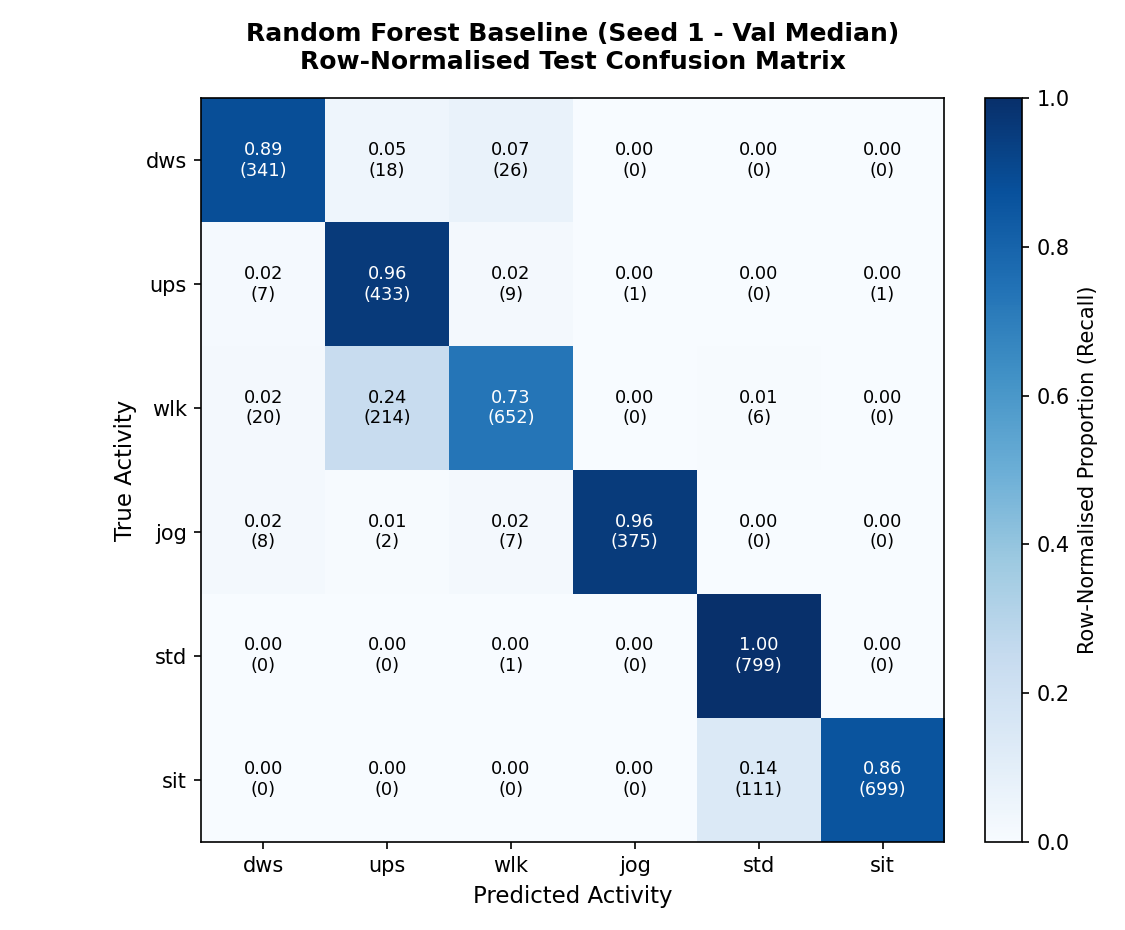


FIGURE 11: PyTorch MLP Confusion Matrix (outputs/figures/fig11_cm_mlp.png)


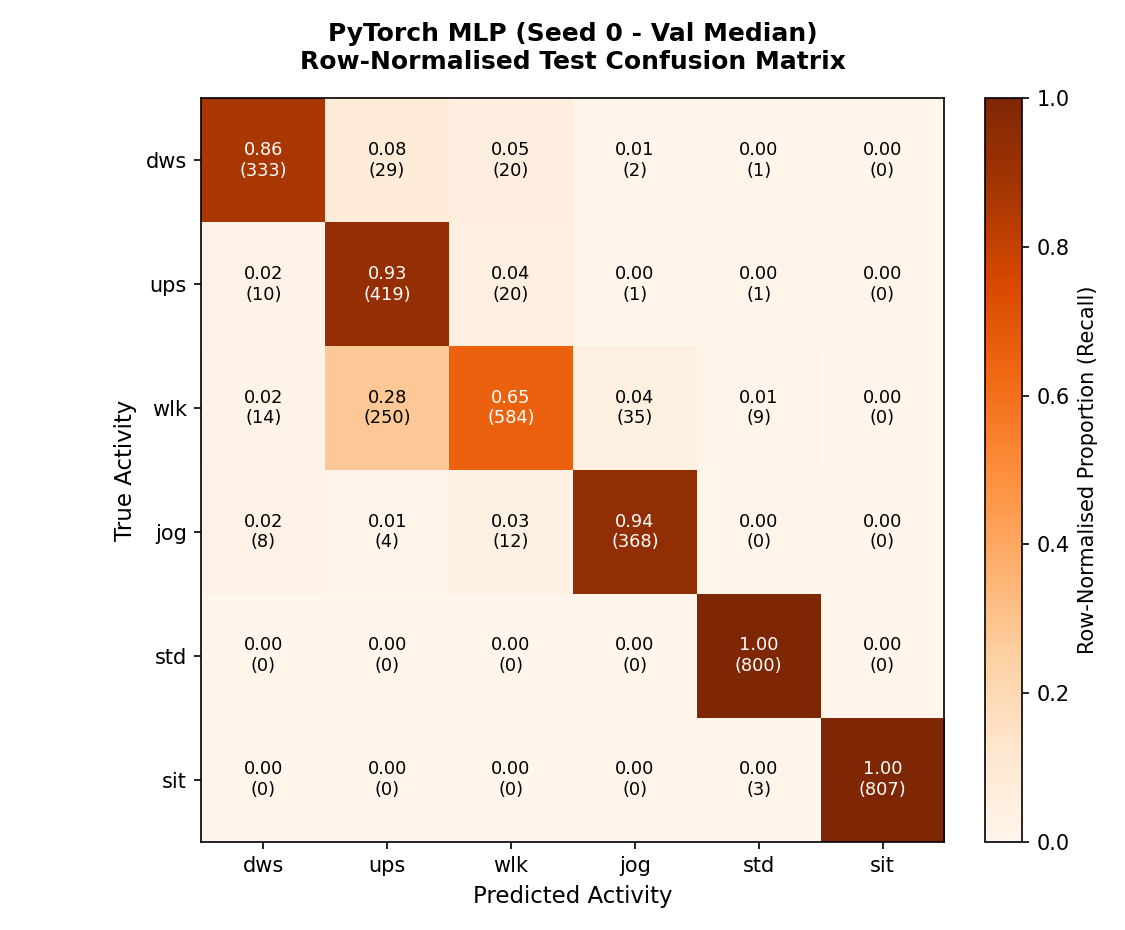


FIGURE 12: PyTorch 1D-CNN Confusion Matrix (outputs/figures/fig12_cm_cnn.png)


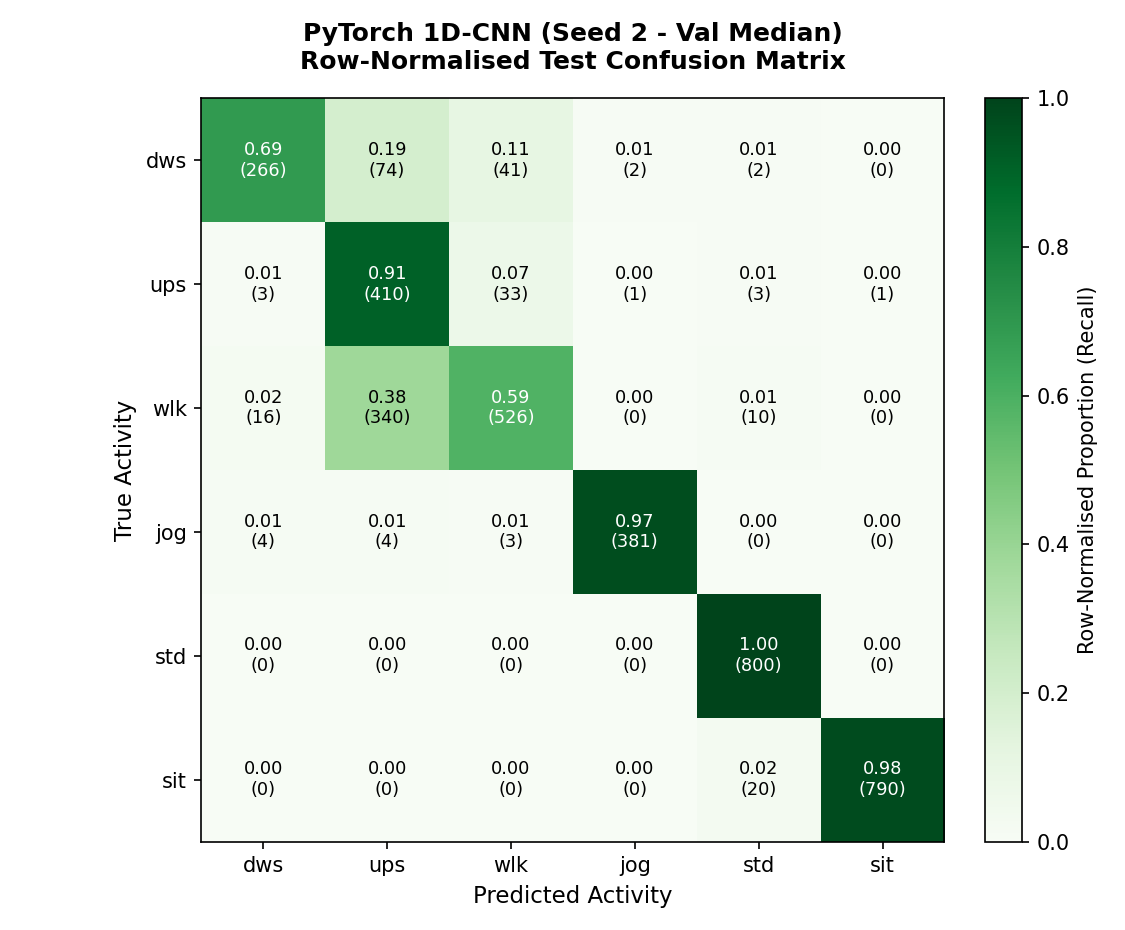

In [7]:
# Cell 12: Visual Inspection of Confusion Matrices (Figures 10, 11, 12)
print("=" * 70)
print("FIGURE 10: Baseline Random Forest Confusion Matrix (outputs/figures/fig10_cm_rf.png)")
print("=" * 70)
ipd.display(ipd.Image(filename="outputs/figures/fig10_cm_rf.png"))

print("\n" + "=" * 70)
print("FIGURE 11: PyTorch MLP Confusion Matrix (outputs/figures/fig11_cm_mlp.png)")
print("=" * 70)
ipd.display(ipd.Image(filename="outputs/figures/fig11_cm_mlp.png"))

print("\n" + "=" * 70)
print("FIGURE 12: PyTorch 1D-CNN Confusion Matrix (outputs/figures/fig12_cm_cnn.png)")
print("=" * 70)
ipd.display(ipd.Image(filename="outputs/figures/fig12_cm_cnn.png"))


### Interpretation of Figures 10, 11 and 12 (Confusion Matrices)

Each row shows where the windows of one true activity ended up (rows add up to 1).
- **Figure 10 (Random Forest, seed 1):** standing 1.00, upstairs 0.96, jogging 0.96. Walking is only 0.73 correct: 0.24 of walking windows are predicted as upstairs. 0.14 of sitting windows are predicted as standing.
- **Figure 11 (MLP, seed 0):** standing and sitting are both 1.00. Walking is 0.65 correct, with 0.28 predicted as upstairs. Downstairs is 0.86, with 0.08 predicted as upstairs.
- **Figure 12 (1D-CNN, seed 2):** the same walking-to-upstairs problem is worst here (0.38), and downstairs is weaker (0.69 correct; 0.19 predicted as upstairs).

All three models fail in the same place, which suggests the problem is in the data (walking and stairs look alike for some people and phone positions), not in one architecture.


FIGURE 13: Per-Class F1 Comparison Across Models (outputs/figures/fig13_per_class_f1.png)


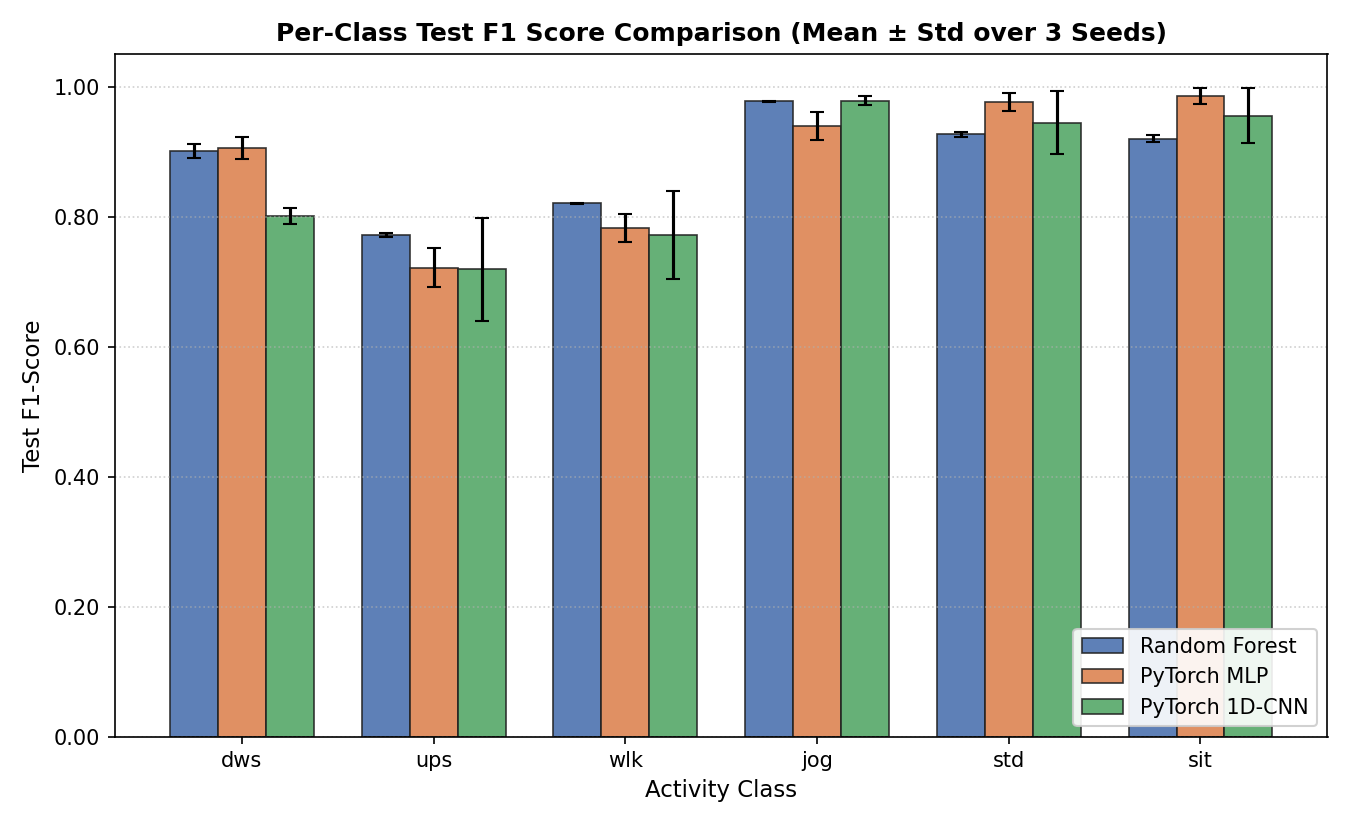


FIGURE 14: Validation vs Test Generalization Gap (outputs/figures/fig14_val_vs_test.png)


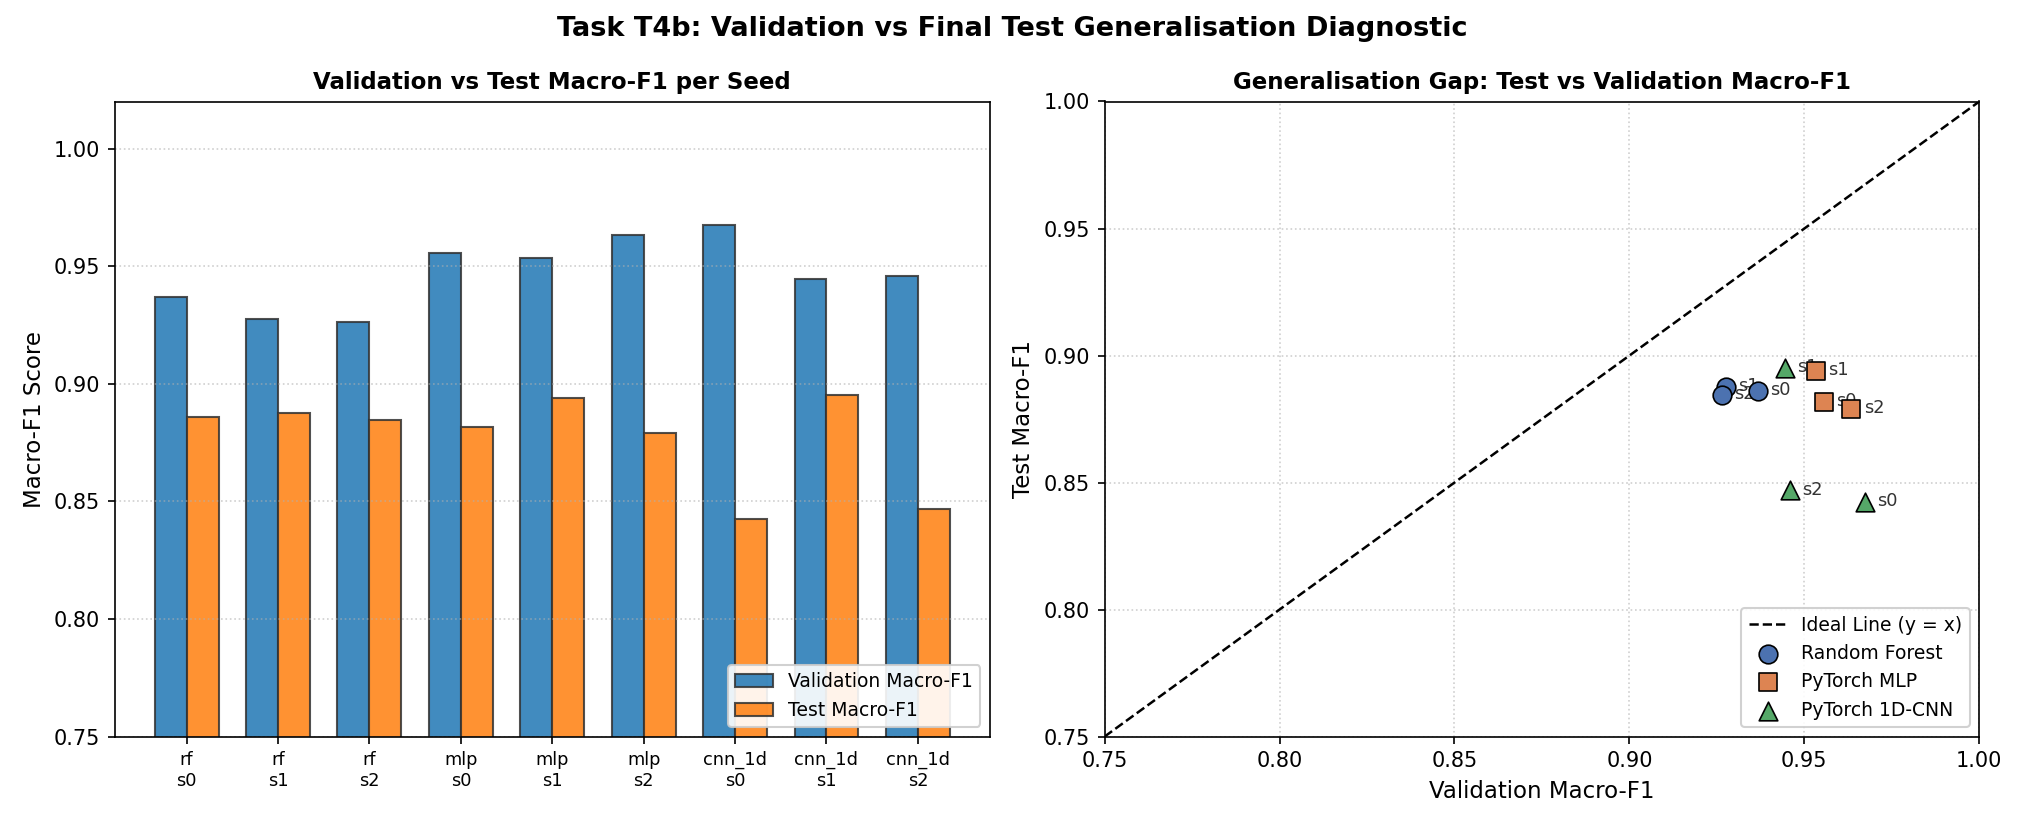

In [8]:
# Cell 14: Visual Inspection of Per-Class F1 & Generalization Gap (Figures 13 & 14)
print("=" * 70)
print("FIGURE 13: Per-Class F1 Comparison Across Models (outputs/figures/fig13_per_class_f1.png)")
print("=" * 70)
ipd.display(ipd.Image(filename="outputs/figures/fig13_per_class_f1.png"))

print("\n" + "=" * 70)
print("FIGURE 14: Validation vs Test Generalization Gap (outputs/figures/fig14_val_vs_test.png)")
print("=" * 70)
ipd.display(ipd.Image(filename="outputs/figures/fig14_val_vs_test.png"))


### Interpretation of Figures 13 and 14

- **Figure 13 (per-class F1, mean ± std over 3 seeds):** all models do well on jogging, standing and sitting, and worst on upstairs and walking. The CNN is clearly behind on downstairs and has the widest error bars (least stable), especially on upstairs and walking. The MLP is best on standing and sitting; the RF is best on walking.
- **Figure 14 (validation vs test):** every model scores lower on test. Validation means: RF 0.9302, MLP 0.9574, CNN 0.9525. Test means: RF 0.8860, MLP 0.8849, CNN 0.8615. The gap is smallest for the RF (0.0442) and largest for the CNN (0.0911). One possible reason is that hand-made summary features are less sensitive to individual differences, but this was not tested.


In [9]:
# Cell 16: Optional Re-Evaluation Execution (Guarded by RUN_TRAINING)
if RUN_TRAINING:
    print("RUN_TRAINING is True: Re-running evaluation suite via src/evaluate.py...")
    from src.evaluate import evaluate_all_models
    # evaluate_all_models()
else:
    print("RUN_TRAINING is False: Evaluation bypassed (reading verified outputs from outputs/metrics/).")


RUN_TRAINING is False: Evaluation bypassed (reading verified outputs from outputs/metrics/).
